<a href="https://colab.research.google.com/github/bimamj/PCVK_2026/blob/main/Modul7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 Practical

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

### Global Threshold 200

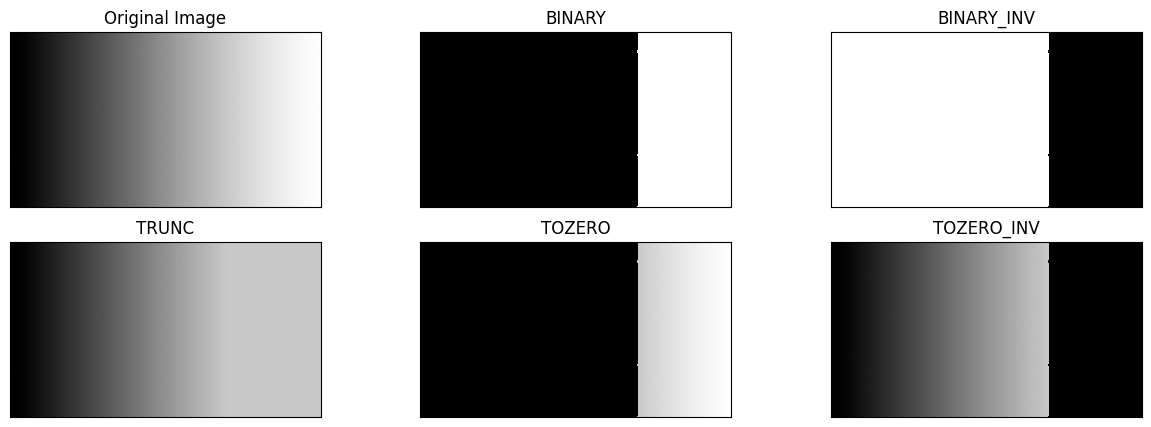

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/gradient.jpg')
img = cv.imread(filename)
thresh = 200 #nilai Threshold yang ditentukan
maxval=255
#1. threshold binary jika pixel di img>127, maka thresh1 bernilai 1(putih) selain itu bernilai 0(hitam)
ret,thresh1 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY)

#2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai maxval
ret,thresh2 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY_INV)

#3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain itu akan bernilai tetap
ret,thresh3 = cv.threshold(img,thresh,maxval,cv.THRESH_TRUNC)

#4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu akan bernilai 0
ret,thresh4 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO)

#5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai tetap
ret,thresh5 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO_INV)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]
plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

### Manual Adaptive Threshold

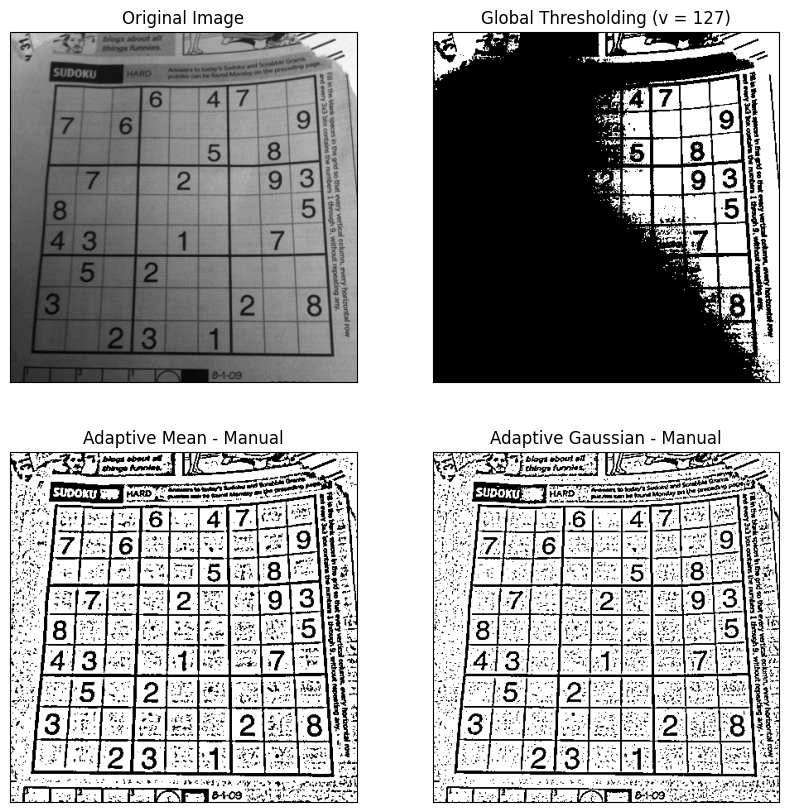

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/sudoku-original.jpg')

citra = cv.imread(filename)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

def create_gaussian_kernel(size=11, sigma=2.0):
  k = size // 2
  x, y = np.mgrid[-k : k + 1, -k : k + 1]
  # Gaussian 2D: exp(-(x^2 + y^2) / (2 * sigma^2))
  kernel = np.exp(-(x**2 + y**2) / (2.0 * sigma**2))
  return kernel / np.sum(kernel)

def adaptive_mean_manual(img, window_size=11, C=2):
  pad = window_size // 2
  padded = np.pad(img, pad, mode='reflect')
  # 11x11 window
  windows = np.lib.stride_tricks.sliding_window_view(
      padded, (window_size, window_size)
  )

  # local mean
  local_mean = windows.mean(axis=(2, 3))

  # local thresh: T(x, y) = mean - C
  thresh_local = local_mean - C

  # compare ori pixel value and local thresh
  return np.where(img > thresh_local, 255, 0).astype(np.uint8)

def adaptive_gaussian_manual(img, window_size=11, C=2, sigma=2.0):
  pad = window_size // 2
  padded = np.pad(img, pad, mode='reflect')

  # kernel Gaussian 11x11, sigma = 2
  kernel = create_gaussian_kernel(window_size, sigma)

  # 11x11 local window
  windows = np.lib.stride_tricks.sliding_window_view(
      padded, (window_size, window_size)
  )

  # local gaussian mean weight
  local_gaussian = np.sum(windows * kernel, axis=(2, 3))

  # local thresh: T(x, y) = gaussian_mean - C
  thresh_local = local_gaussian - C

  # compare ori pixel value and local thresh
  return np.where(img > thresh_local, 255, 0).astype(np.uint8)

thresh = 127
# Global Thresholding Manual (v = 127)
th1 = np.where(gray > thresh, 255, 0).astype(np.uint8)

# Adaptive Mean Thresholding Manual (Window 11x11, C = 2)
th2 = adaptive_mean_manual(gray, window_size=11, C=2)

# Adaptive Gaussian Thresholding Manual (Window 11x11, C = 2, Sigma = 2)
th3 = adaptive_gaussian_manual(gray, window_size=11, C=2, sigma=2.0)

titles = [
    'Original Image',
    'Global Thresholding (v = 127)',
    'Adaptive Mean - Manual',
    'Adaptive Gaussian - Manual',
]

citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(10, 10))
for i in range(len(citra2)):
  plt.subplot(2, 2, i + 1)
  plt.imshow(citra2[i], 'gray')
  plt.title(titles[i])
  plt.xticks([])
  plt.yticks([])
plt.show()

### Lena GS LC2 Global threshold vs Otsu

93


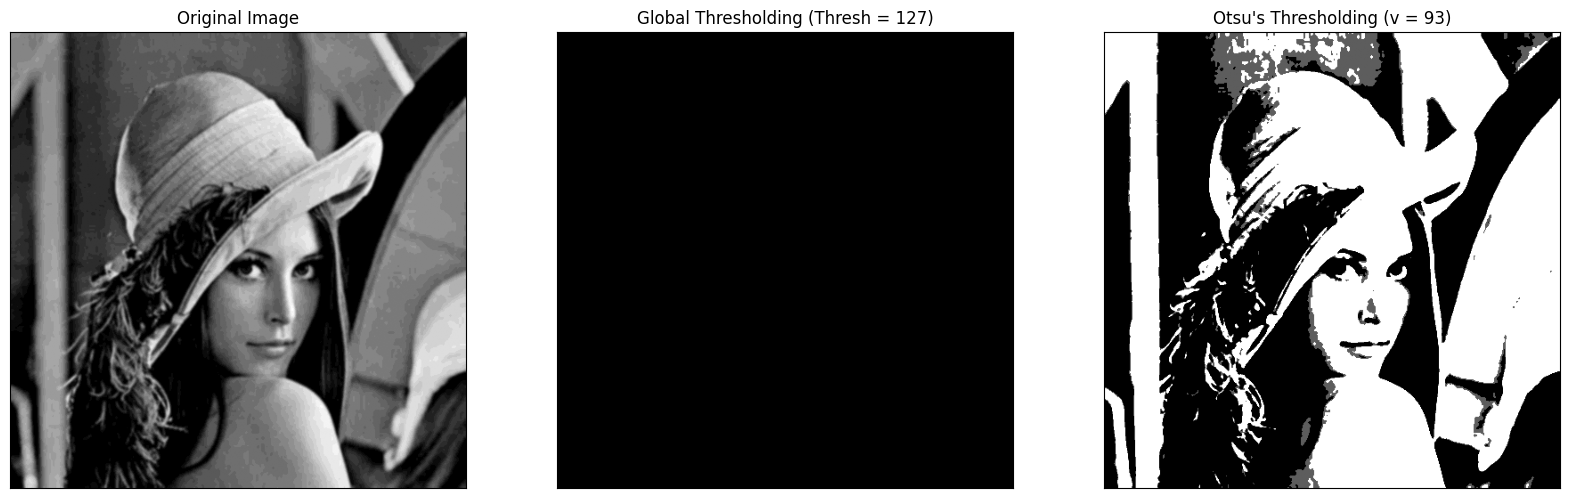

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    if pcb == 0 or pcf == 0:
      continue

    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value

  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Original Image', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

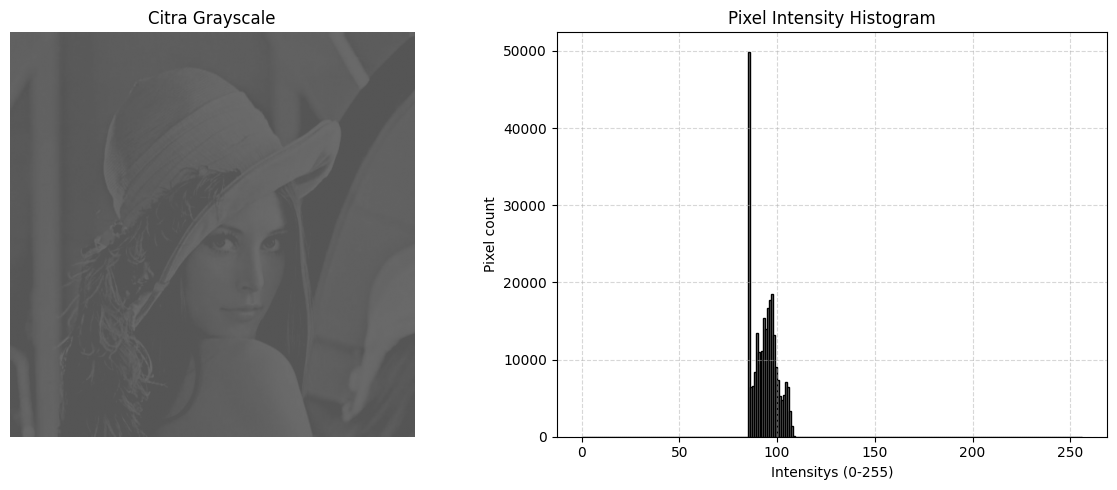

In [ ]:
filename = '/content/drive/MyDrive/PCVK/lena_gs_lc2.jpg'
img = cv.imread(filename, 0)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Citra Grayscale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray', edgecolor='black')
plt.title('Pixel Intensity Histogram')
plt.xlabel('Intensitys (0-255)')
plt.ylabel('Pixel count')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Standard binary thresholding follow the formula vlue 1 if greater than T and 0 if lesser or same than T. Because the chosen threshold is T = 127, every single pixel in the image has an intensity value less than 127 so the image lena_gs_lc2 is set to black (0). To reveal the features of the image, the threshold must be placed inside the active pixel distribution range (between 85 and 108)

### KTP Fulan Global Threshold vs Otsu

166


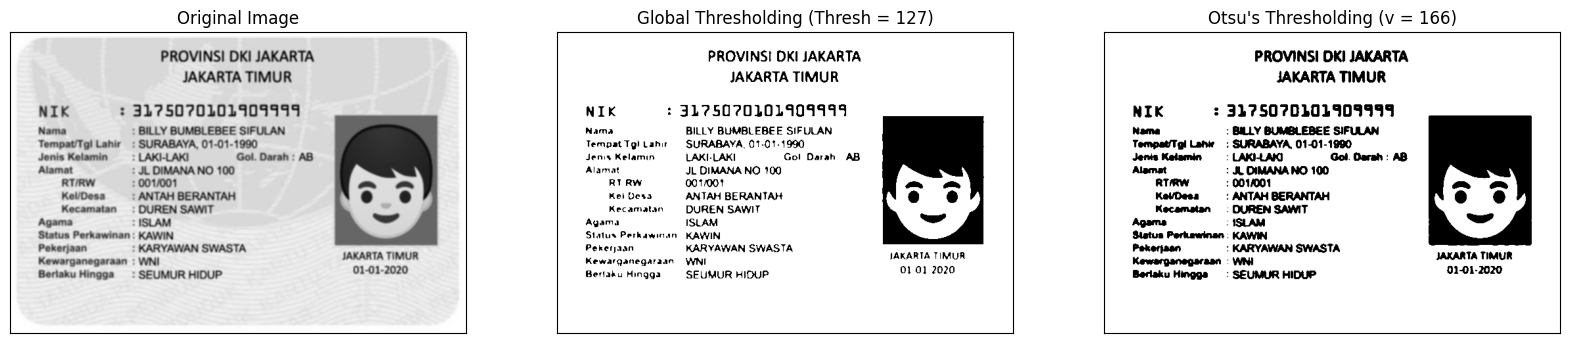

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/ktp1.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    if pcb == 0 or pcf == 0:
      continue

    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value

  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Original Image', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

### Region Based Segmentation data.coins()



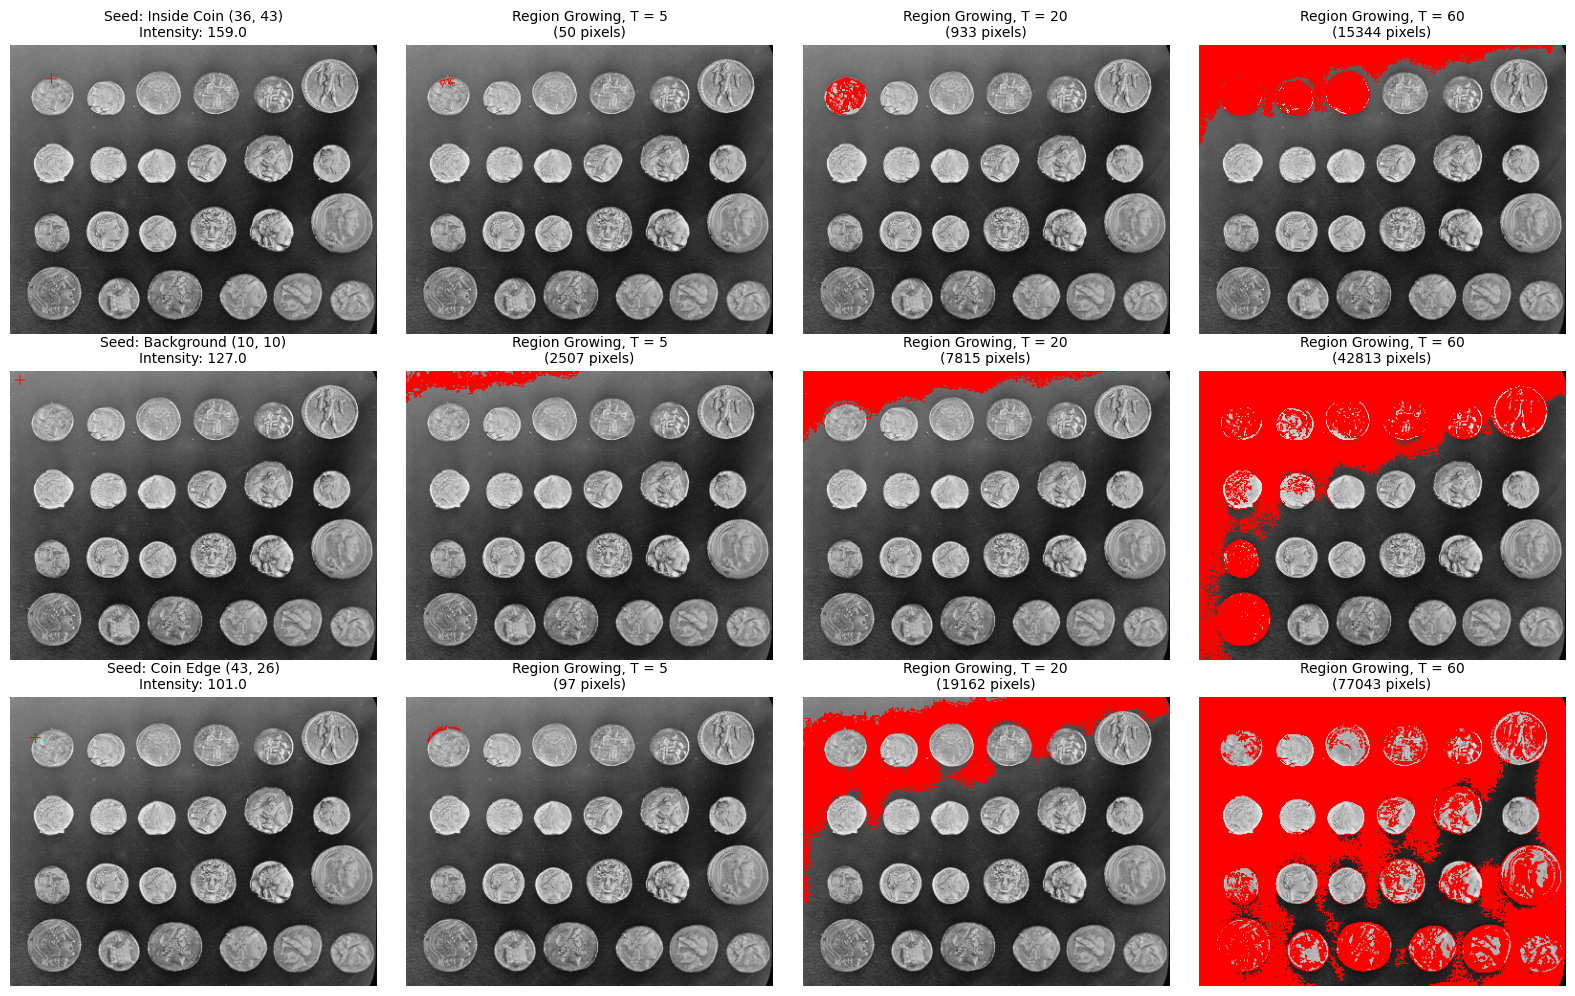

In [ ]:
from skimage import data
from skimage.segmentation import flood
img = data.coins()


# 2. Region Growing Algorithm Implementation (BFS)
def region_growing(img, seed, T):
  H, W = img.shape
  mask = np.zeros((H, W), dtype=bool)
  visited = np.zeros((H, W), dtype=bool)

  sr, sc = seed
  seed_val = float(img[sr, sc])

  queue = deque([(sr, sc)])
  visited[sr, sc] = True
  mask[sr, sc] = True

  neighbors = [
      (-1, -1),
      (-1, 0),
      (-1, 1),
      (0, -1),
      (0, 1),
      (1, -1),
      (1, 0),
      (1, 1),
  ]

  while queue:
    r, c = queue.popleft()

    for dr, dc in neighbors:
      nr, nc = r + dr, c + dc
      # Check image boundary
      if 0 <= nr < H and 0 <= nc < W and not visited[nr, nc]:
        visited[nr, nc] = True
        if abs(float(img[nr, nc]) - seed_val) <= T:
          mask[nr, nc] = True
          queue.append((nr, nc))

  return mask


def mark_seed_on_image(img, seed, cross_size=5):
  rgb = np.stack([img] * 3, axis=-1)
  r, c = seed
  r_min, r_max = max(0, r - cross_size), min(img.shape[0], r + cross_size + 1)
  c_min, c_max = max(0, c - cross_size), min(img.shape[1], c + cross_size + 1)

  rgb[r_min:r_max, c] = [255, 0, 0]  # Vertical red line
  rgb[r, c_min:c_max] = [255, 0, 0]  # Horizontal red line
  return rgb


def overlay_mask(img, mask):
  rgb = np.stack([img] * 3, axis=-1)
  rgb[mask] = [255, 0, 0]  # Set mask pixels to RED
  return rgb

seeds = [
    (36, 43),  # Seed 1: Inside a coin
    (10, 10),  # Seed 2: In the background
    (43, 26),  # Seed 3: On the edge of a coin
]

seed_labels = [
    'Inside Coin (36, 43)',
    'Background (10, 10)',
    'Coin Edge (43, 26)',
]

thresholds = [5, 20, 60]

fig, axes = plt.subplots(
    nrows=len(seeds), ncols=len(thresholds) + 1, figsize=(16, 10)
)

for i, (seed, label) in enumerate(zip(seeds, seed_labels)):
  seed_val = img[seed[0], seed[1]]

  img_with_seed = mark_seed_on_image(img, seed)
  axes[i, 0].imshow(img_with_seed)
  axes[i, 0].set_title(
      f'Seed: {label}\nIntensity: {seed_val:.1f}', fontsize=10
  )
  axes[i, 0].axis('off')

  for j, T in enumerate(thresholds):
    mask = region_growing(img, seed, T)
    pixel_count = np.sum(mask)
    result_img = overlay_mask(img, mask)

    axes[i, j + 1].imshow(result_img)
    axes[i, j + 1].set_title(
        f'Region Growing, T = {T}\n({pixel_count} pixels)', fontsize=10
    )
    axes[i, j + 1].axis('off')

plt.tight_layout()
plt.show()


### Region Based Segmentation data.coins() using skimage.segmentation.flood()

*** Seed (row, column): (36, 43) | intensity: 159.000000
Tolerance 5: 21 pixe
Tolerance 20: 919 pixe
Tolerance 60: 15253 pixe


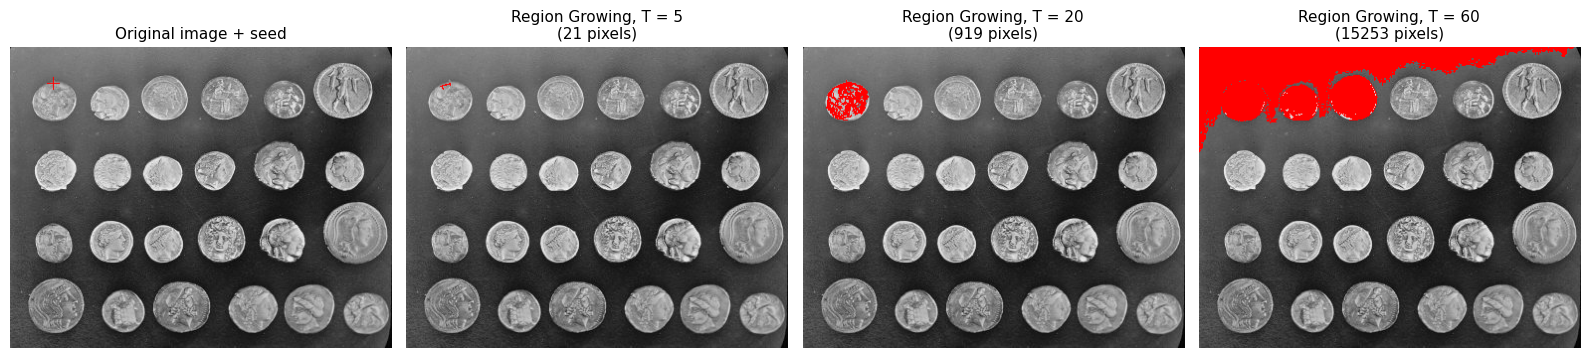

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data
from skimage.segmentation import flood

gray = data.coins()

seed = (36, 43)
seed_intensity = gray[seed[0], seed[1]]
tolerances = [5, 20, 60]

def draw_seed_marker(img, seed_pt):
  rgb = np.stack([img] * 3, axis=-1)
  r, c = seed_pt
  rgb[max(0, r - 6) : min(img.shape[0], r + 7), c] = [255, 0, 0]
  rgb[r, max(0, c - 6) : min(img.shape[1], c + 7)] = [255, 0, 0]
  return rgb

print(f'*** Seed (row, column): {seed} | intensity: {seed_intensity:.6f}')
for T in tolerances:
  m = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
  print(f'Tolerance {T}: {np.sum(m)} pixe')

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(draw_seed_marker(gray, seed))
axes[0].set_title('Original image + seed', fontsize=11)
axes[0].axis('off')

for idx, T in enumerate(tolerances):
  mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
  pixel_count = np.sum(mask)

  result_rgb = np.stack([gray] * 3, axis=-1)
  result_rgb[mask] = [255, 0, 0]

  axes[idx + 1].imshow(result_rgb)
  axes[idx + 1].set_title(
      f'Region Growing, T = {T}\n({pixel_count} pixels)', fontsize=11
  )
  axes[idx + 1].axis('off')

plt.tight_layout()
plt.show()

### Color segmentation KTP

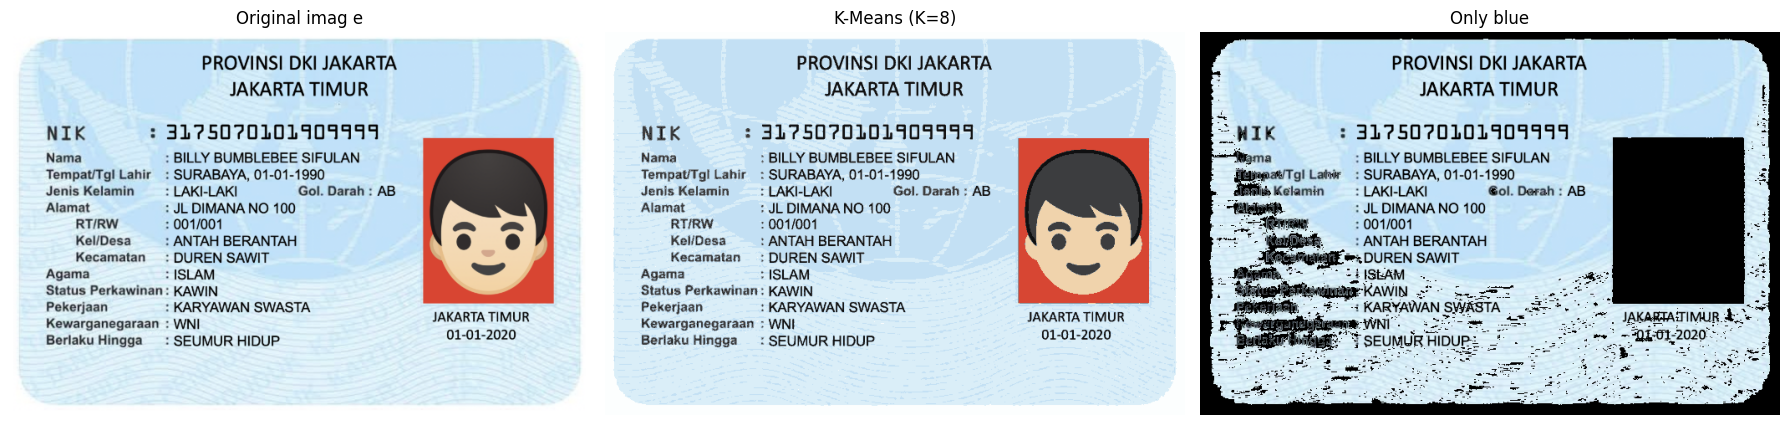

In [ ]:
from sklearn.cluster import KMeans

filename = '/content/drive/MyDrive/PCVK/ktp1.jpg'
img_bgr = cv.imread(filename)

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)

# 2. Reshape to 2D matrix 2D fr K-Means
h, w, c = img_rgb.shape
pixels = img_rgb.reshape((-1, 3))
pixels_float = np.float32(pixels)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(pixels_float)
centers = np.uint8(kmeans.cluster_centers_)

segmented_pixels = centers[labels]
segmented_img = segmented_pixels.reshape((h, w, c))

H = img_hsv[:, :, 0]
S = img_hsv[:, :, 1]
V = img_hsv[:, :, 2]

kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

only_blue_img = np.zeros_like(img_rgb)
only_blue_img[kelompok_biru] = img_rgb[kelompok_biru]

titles = ['Original imag e', f'K-Means (K={k})', 'Only blue']
images = [img_rgb, segmented_img, only_blue_img]

plt.figure(figsize=(18, 6))
for i in range(len(images)):
  plt.subplot(1, 3, i + 1)
  plt.imshow(images[i])
  plt.title(titles[i], fontsize=12)
  plt.axis('off')

plt.tight_layout()
plt.show()

## Group Assignment
Excell Christian Wulantoro Sadik / 244107020227

Muhammad Bima Juliansyah / 244107020123

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


=== Memproses Citra 1: /content/drive/MyDrive/PCVK/ktp_bima_blur.jpg ===


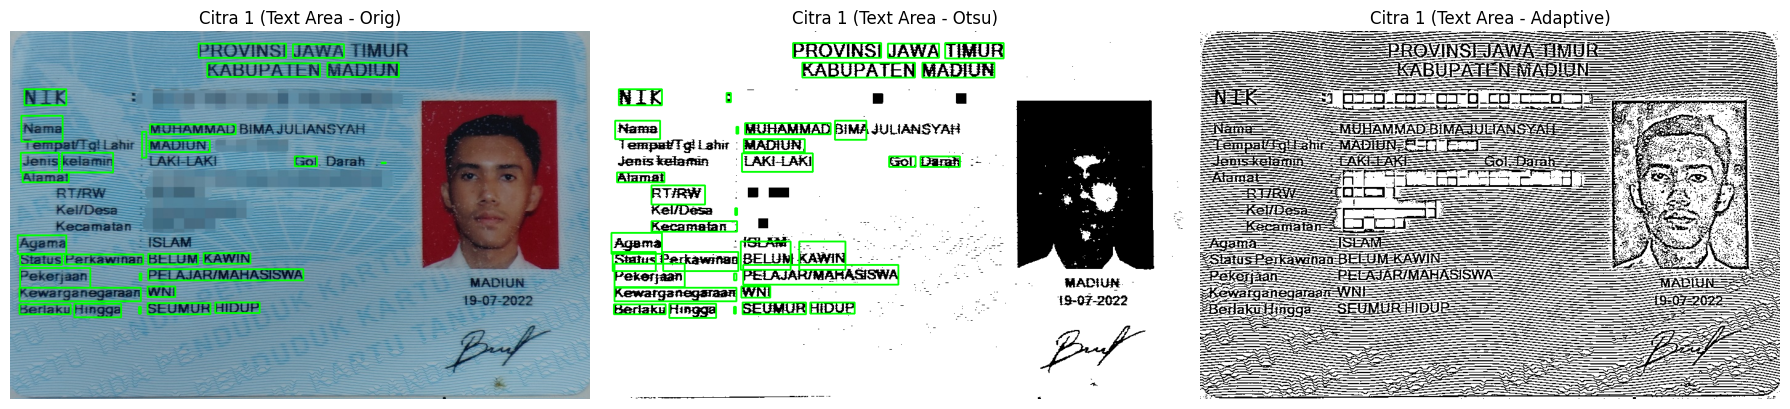


--- OCR text result(Citra 1) ---
[Original]:
PROVINSI JAWA HMUR
KABUPATEN MADIUN
NIK “
Nama MUHAMMAD BIMAJULIANSYAH
TempatTgiLahir : MADIUN,

Jenis kelamin KAKE--AKI Gol. Darah —
Alamat

RERW

Kel/Desa-— —

Kecamatan
Agama SISTAM
Status Perkawinan BELUM KAWIN
Pekerjaan : PELAJAR/MAHASISWA TAK
Kewarganegaraan WNI 197 U22

Berlaku Hingga : SEUMUR HIDUP
----------------------------------------
[Otsu]:
PROVINSI JAWA TIMUR
KABUPATEN MADIUN

NIK : - -
Nama 1 MUHAMMAD BIMA JULIANSYAH
TempatTgi Lahir MADIUN,
Jen kelaman LAKI-LAKI Sol. Darah :-
Alamat

RTRW 2. -

KellDesa :

Kecamatan. TH
Agema 2 ISLAM “
Status Perkawinan BELUM KAWIN ena
Pekerjaan : PELAJAR/MAHASISWA
Kewarganegaraan WNI
Berlaku Hingga : SEUMUR HIDUP
----------------------------------------
[Adaptive]:
5.

21 UBI YAP ESA
aa igtel JAraatY

inaga. SEUMUR NDUB
----------------------------------------
=== Memproses Citra 2: /content/drive/MyDrive/PCVK/ktp_excell_blur.jpg ===


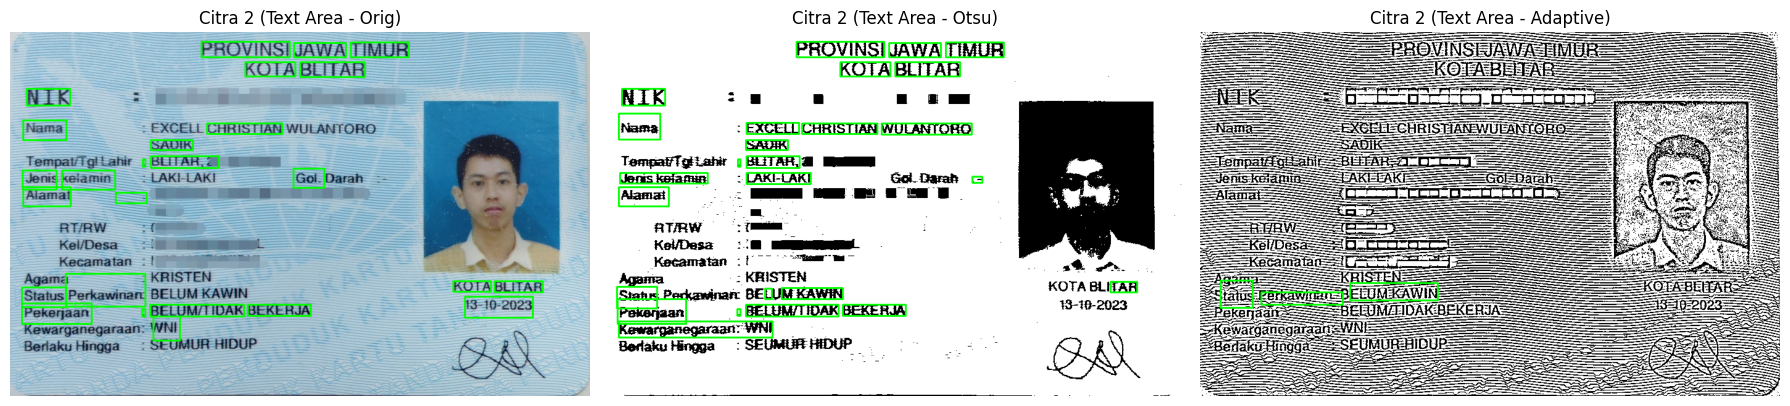


--- OCR text result(Citra 2) ---
[Original]:
PROVINSI JAWA TIMUR

KOTA BLITAR
NIK - B - Ma Mn
Nama 2 EXCEL CHRISTIAN WULANTORO:
SADIK
Tempatgitahir : BUTAR 2
Jenis kelamin LAKI-LAKI Goi- Darah —

Alamat — TN Tn IE

Status Perkawinan: AA KOTA BLITAR
Pekerjaan : BELUM/TIDAK BEKERJA 1310-2023

Kewarganegaraan: WNI
Berlaku Hingga: SEUMUR HIDUP “ GI
----------------------------------------
[Otsu]:
PROVINSI JAWA TIMUR

KOTA BLITAR
NIK - - 1 5.—
Nama : EXGELL CHRISTIAN WULANTORO
SADIK
TempatTgitahi : BUTAR, 2 MAN
Joniskelamin —: LAKI-LAKI Gol Darah --

Alamat Da MAAN IN nas”

Nm.

Agama JAUSTEN KOTABLI
TAR
erkaminarc BELUM KAWIN
Status Pi BELU 19-19-2523

Pekerjaan : BELUM/TIDAK BEKERJA

Kewarganegaraan WNI
----------------------------------------
[Adaptive]:
229

tatus Perkawinan BELUMKAWIN
“Pekerja. ELUM/IDAKBEKEHIA

Ewarganegaraat AN!
mag SEUAU HOUP Es

—— 5
----------------------------------------


In [4]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytesseract
from pytesseract import Output

filename1 = '/content/drive/MyDrive/PCVK/ktp_bima_blur.jpg'
filename2 = '/content/drive/MyDrive/PCVK/ktp_excell_blur.jpg'

def process_and_ocr(image_path, lang='ind', psm=3, conf_thresh=60):
  img_bgr = cv.imread(image_path)
  if img_bgr is None:
    raise FileNotFoundError(f'File tidak ditemukan: {image_path}')

  img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
  gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

  # Ori
  img_color = img_rgb.copy()

  # Otsu
  _, th_otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
  img_otsu_rgb = cv.cvtColor(th_otsu, cv.COLOR_GRAY2RGB)

  # Adaptive
  th_adaptive = cv.adaptiveThreshold(
      gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2
  )
  img_adaptive_rgb = cv.cvtColor(th_adaptive, cv.COLOR_GRAY2RGB)

  variants = {
      'Original': (img_color, img_rgb),
      'Otsu': (img_otsu_rgb, th_otsu),
      'Adaptive': (img_adaptive_rgb, th_adaptive),
  }

  custom_config = f'--psm {psm}'
  results_text = {}
  bounding_imgs = {}

  for name, (img_disp, img_proc) in variants.items():
    # 1. Read text string
    text = pytesseract.image_to_string(
        img_proc, lang=lang, config=custom_config
    )
    results_text[name] = text

    # 2. Area detection
    data = pytesseract.image_to_data(
        img_proc, lang=lang, config=custom_config, output_type=Output.DICT
    )

    img_box = img_disp.copy()
    n_boxes = len(data['text'])
    for i in range(n_boxes):
      try:
        conf = float(data['conf'][i])
      except (ValueError, TypeError):
        conf = -1

      if conf > conf_thresh and data['text'][i].strip() != '':
        x, y, w, h = (
            data['left'][i],
            data['top'][i],
            data['width'][i],
            data['height'][i],
        )
        cv.rectangle(img_box, (x, y), (x + w, y + h), (0, 255, 0), 2)

    bounding_imgs[name] = img_box

  return variants, results_text, bounding_imgs

files = {'Citra 1': filename1, 'Citra 2': filename2}
all_results = {}

for label, filepath in files.items():
  print(f'=== Memproses {label}: {filepath} ===')
  variants, texts, box_imgs = process_and_ocr(
      filepath, lang='ind', psm=3, conf_thresh=60
  )
  all_results[label] = {
      'variants': variants,
      'texts': texts,
      'box_imgs': box_imgs,
  }

  # 3 image variant and green box area
  plt.figure(figsize=(18, 6))
  titles = ['Text Area - Orig', 'Text Area - Otsu', 'Text Area - Adaptive']
  names = ['Original', 'Otsu', 'Adaptive']

  for i, name in enumerate(names):
    plt.subplot(1, 3, i + 1)
    plt.imshow(box_imgs[name])
    plt.title(f'{label} ({titles[i]})', fontsize=12)
    plt.axis('off')

  plt.tight_layout()
  plt.show()

  print(f'\n--- OCR text result({label}) ---')
  for name in names:
    print(f'[{name}]:\n{texts[name].strip()}\n{"-"*40}')

def evaluate_ocr(true_texts, ocr_color, ocr_otsu, ocr_adaptive):
  rows = []
  correct_counts = {'Ori': 0, 'Otsu': 0, 'Adaptive': 0}

  def clean(text):
    return text.strip().lower()

  for i, item in enumerate(true_texts, 1):
    ref_clean = clean(item)

    c_val = item if ref_clean in clean(ocr_color) else 'MISS'
    o_val = item if ref_clean in clean(ocr_otsu) else 'MISS'
    a_val = item if ref_clean in clean(ocr_adaptive) else 'MISS'

    match_c = ref_clean in clean(ocr_color)
    match_o = ref_clean in clean(ocr_otsu)
    match_a = ref_clean in clean(ocr_adaptive)

    if match_c:
      correct_counts['Ori'] += 1
    if match_o:
      correct_counts['Otsu'] += 1
    if match_a:
      correct_counts['Adaptive'] += 1

    rows.append({
        'No.': i,
        'Original Text': item,
        'OCR Ori': item if match_c else '[False/Missing]',
        'OCR Otsu': item if match_o else '[False/Missing]',
        'OCR Adaptive': item if match_a else '[False/Missing]',
    })

  df = pd.DataFrame(rows)

  acc = {
      'Original': (correct_counts['Berwarna'] / len(true_texts)) * 100,
      'Otsu': (correct_counts['Otsu'] / len(true_texts)) * 100,
      'Adaptive': (correct_counts['Adaptive'] / len(true_texts)) * 100,
  }

  return df, acc